# Alpha Power


## Setup
Experiment: `alpha_power`. Each trial starts from scratch using `alpha_sweep/models.py`: 6 layers, 6 heads, width 384, tied embeddings, vocabulary 50257, sequence length 1024, and FineWeb10B data. Global batch: 512 sequences; device batch: 8; 100 steps, seeds [2, 3, 4, 5, 6], 1048576 validation tokens every 25 steps and at the end. AdamW learning rate is 0.0036; matrix optimizer learning rate is 0.00036 with EMA momentum 0.95 and linear warmdown. BF16 autocast is used for training. Exact source hashes and launch command are embedded below. Dataset shard checksums, GPU and library versions are not captured in this notebook; consult the original trial logs. CUDA may be nondeterministic.

## Spectral transformation
For momentum $M=U\operatorname{diag}(\sigma)V^\top$, each matrix block is first Frobenius-normalized. Linear interpolation maps active singular values to $(1-\alpha)\sigma_i+\alpha$; values of $\alpha>1$ reverse the ordering of active directions. Clipping bounds active values relative to their median. Selective flattening replaces chosen active singular values with 1; low-rank orthogonalization replaces the retained top directions with 1 and the rest with 0. Values at or below $10^{-7}$ are not selected. The optimizer rescales each output to Frobenius norm $\sqrt{\min(m,n)}$ unless it is zero, so unselected values also change scale. The power experiment instead uses the regularized Gram eigendecomposition from the alpha sweep; its alpha=1 baseline is not the exact-SVD Muon baseline.

The alpha power experiment completed 15 of 15 trials; 0 diverged. Among configurations completed for every seed, alpha=1.0625 had the lowest mean final validation loss (5.893364) over 5 seed(s). This is the best tested configuration, not evidence of a global optimum.

Every trial used 100 steps and the same GPT architecture and data loader as the alpha sweep. Update norms were matched per matrix block; validation curves in the notebook are rounded console values, while final rankings use full-precision results. Elapsed time includes setup and validation; optimizer-only overhead was not measured.


In [1]:
import json
import matplotlib.pyplot as plt
data = json.loads('[{"label": "alpha=1", "seed": 2, "status": "completed", "final": 5.89906644821167, "seconds": 210.10068203299306, "validation": [[0, 10.9802], [25, 6.5827], [50, 6.1536], [75, 5.9941], [100, 5.8991]], "training": [[1, 10.9699], [2, 10.0477], [3, 9.1166], [4, 8.4152], [5, 7.9185], [6, 8.0626], [7, 7.5462], [8, 7.6454], [9, 7.6506], [10, 7.7787], [11, 7.2004], [12, 7.3412], [13, 7.1465], [14, 7.2767], [15, 6.8352], [16, 6.9354], [17, 6.5442], [18, 7.5852], [19, 6.497], [20, 6.5833], [21, 6.8662], [22, 6.6122], [23, 6.7395], [24, 6.6517], [25, 6.869], [26, 6.9179], [27, 6.6741], [28, 6.0698], [29, 6.539], [30, 6.4037], [31, 6.2026], [32, 6.4457], [33, 6.0308], [34, 6.5245], [35, 6.3734], [36, 6.2929], [37, 6.3654], [38, 6.3445], [39, 5.9469], [40, 5.9667], [41, 6.1176], [42, 6.0296], [43, 6.1466], [44, 6.0444], [45, 5.9197], [46, 6.2425], [47, 6.1856], [48, 6.1323], [49, 5.95], [50, 6.1106], [51, 6.2013], [52, 5.9523], [53, 6.1256], [54, 5.9688], [55, 6.3066], [56, 6.0808], [57, 6.1505], [58, 6.0579], [59, 6.0939], [60, 5.647], [61, 5.8466], [62, 5.8155], [63, 5.9735], [64, 5.8583], [65, 6.1195], [66, 6.261], [67, 6.1807], [68, 6.3454], [69, 6.1029], [70, 5.805], [71, 5.8441], [72, 5.8963], [73, 6.053], [74, 6.0323], [75, 6.1451], [76, 6.5433], [77, 5.7342], [78, 5.8918], [79, 5.6953], [80, 6.0277], [81, 5.8945], [82, 5.8895], [83, 6.1701], [84, 6.0923], [85, 6.0648], [86, 5.7539], [87, 6.0125], [88, 6.7762], [89, 5.9965], [90, 6.2122], [91, 6.0817], [92, 5.7727], [93, 5.69], [94, 6.0155], [95, 6.0821], [96, 5.6863], [97, 6.1077], [98, 6.0103], [99, 6.1035], [100, 5.8724]]}, {"label": "alpha=1", "seed": 3, "status": "completed", "final": 5.890590667724609, "seconds": 214.9166403899435, "validation": [[0, 10.9942], [25, 6.5527], [50, 6.1447], [75, 5.9861], [100, 5.8906]], "training": [[1, 11.0038], [2, 10.1597], [3, 9.2609], [4, 8.5297], [5, 7.9819], [6, 8.0262], [7, 7.4682], [8, 7.5606], [9, 7.5602], [10, 7.7508], [11, 7.174], [12, 7.2551], [13, 6.9893], [14, 7.1484], [15, 6.8131], [16, 6.9458], [17, 6.5133], [18, 7.4818], [19, 6.392], [20, 6.545], [21, 6.8475], [22, 6.5869], [23, 6.7073], [24, 6.6234], [25, 6.8301], [26, 6.9284], [27, 6.6871], [28, 6.0997], [29, 6.5282], [30, 6.402], [31, 6.2054], [32, 6.4288], [33, 6.0043], [34, 6.5223], [35, 6.3804], [36, 6.2875], [37, 6.3615], [38, 6.3345], [39, 5.9259], [40, 5.9745], [41, 6.1126], [42, 6.0064], [43, 6.1312], [44, 6.052], [45, 5.9224], [46, 6.238], [47, 6.1673], [48, 6.1384], [49, 5.9369], [50, 6.0923], [51, 6.1851], [52, 5.9786], [53, 6.1139], [54, 5.9667], [55, 6.304], [56, 6.066], [57, 6.1472], [58, 6.0727], [59, 6.1058], [60, 5.6539], [61, 5.8498], [62, 5.7942], [63, 5.966], [64, 5.8601], [65, 6.111], [66, 6.2613], [67, 6.1578], [68, 6.3523], [69, 6.0973], [70, 5.8041], [71, 5.8365], [72, 5.9027], [73, 6.0352], [74, 6.0206], [75, 6.1275], [76, 6.5203], [77, 5.7184], [78, 5.8833], [79, 5.6818], [80, 6.019], [81, 5.8916], [82, 5.9043], [83, 6.1724], [84, 6.0654], [85, 6.0743], [86, 5.7663], [87, 6.0058], [88, 6.7869], [89, 5.9851], [90, 6.1965], [91, 6.0758], [92, 5.7664], [93, 5.6695], [94, 6.0044], [95, 6.0826], [96, 5.6804], [97, 6.0976], [98, 5.9965], [99, 6.1064], [100, 5.8612]]}, {"label": "alpha=1", "seed": 4, "status": "completed", "final": 5.893393516540527, "seconds": 216.63469564099796, "validation": [[0, 10.977], [25, 6.5812], [50, 6.1492], [75, 5.988], [100, 5.8934]], "training": [[1, 10.9729], [2, 10.0646], [3, 9.1395], [4, 8.4477], [5, 7.9499], [6, 8.0417], [7, 7.5255], [8, 7.6384], [9, 7.6469], [10, 7.7975], [11, 7.1871], [12, 7.3027], [13, 7.1416], [14, 7.2783], [15, 6.877], [16, 6.9288], [17, 6.561], [18, 7.6055], [19, 6.4867], [20, 6.603], [21, 6.8793], [22, 6.6049], [23, 6.7444], [24, 6.6575], [25, 6.885], [26, 6.9487], [27, 6.6935], [28, 6.0774], [29, 6.5549], [30, 6.4012], [31, 6.218], [32, 6.4505], [33, 6.0207], [34, 6.5487], [35, 6.3904], [36, 6.296], [37, 6.368], [38, 6.3711], [39, 5.9413], [40, 5.9961], [41, 6.1101], [42, 6.0276], [43, 6.1401], [44, 6.044], [45, 5.9194], [46, 6.2456], [47, 6.1734], [48, 6.085], [49, 5.9452], [50, 6.107], [51, 6.2063], [52, 5.9774], [53, 6.1084], [54, 5.9654], [55, 6.3008], [56, 6.0722], [57, 6.1462], [58, 6.065], [59, 6.1263], [60, 5.6391], [61, 5.8379], [62, 5.804], [63, 5.9725], [64, 5.8529], [65, 6.1121], [66, 6.2374], [67, 6.1646], [68, 6.3464], [69, 6.0966], [70, 5.8045], [71, 5.8236], [72, 5.891], [73, 6.0415], [74, 6.0203], [75, 6.1287], [76, 6.5364], [77, 5.7196], [78, 5.8868], [79, 5.6835], [80, 6.025], [81, 5.8956], [82, 5.9019], [83, 6.1554], [84, 6.0901], [85, 6.0717], [86, 5.76], [87, 6.0035], [88, 6.7766], [89, 5.9823], [90, 6.208], [91, 6.0724], [92, 5.7741], [93, 5.6902], [94, 6.0324], [95, 6.0957], [96, 5.6904], [97, 6.1283], [98, 5.9954], [99, 6.0913], [100, 5.8877]]}, {"label": "alpha=1", "seed": 5, "status": "completed", "final": 5.889518737792969, "seconds": 216.42485687090084, "validation": [[0, 10.9767], [25, 6.5842], [50, 6.1501], [75, 5.9848], [100, 5.8895]], "training": [[1, 10.9787], [2, 10.0234], [3, 9.115], [4, 8.4362], [5, 7.9278], [6, 8.0378], [7, 7.5078], [8, 7.6394], [9, 7.6698], [10, 7.7746], [11, 7.1444], [12, 7.2683], [13, 7.0922], [14, 7.2334], [15, 6.8653], [16, 6.9259], [17, 6.5257], [18, 7.5612], [19, 6.4568], [20, 6.5946], [21, 6.887], [22, 6.6022], [23, 6.7336], [24, 6.636], [25, 6.8531], [26, 6.9252], [27, 6.698], [28, 6.1136], [29, 6.5646], [30, 6.414], [31, 6.2074], [32, 6.4571], [33, 6.0143], [34, 6.541], [35, 6.4067], [36, 6.2649], [37, 6.3608], [38, 6.331], [39, 5.9353], [40, 5.9748], [41, 6.1193], [42, 6.0178], [43, 6.1459], [44, 6.054], [45, 5.9197], [46, 6.2488], [47, 6.1776], [48, 6.0691], [49, 5.9494], [50, 6.1038], [51, 6.2086], [52, 5.97], [53, 6.1227], [54, 5.9596], [55, 6.2981], [56, 6.0778], [57, 6.1529], [58, 6.0628], [59, 6.1063], [60, 5.6518], [61, 5.8412], [62, 5.7971], [63, 5.9713], [64, 5.8551], [65, 6.1287], [66, 6.2585], [67, 6.1681], [68, 6.3544], [69, 6.0972], [70, 5.8041], [71, 5.8228], [72, 5.887], [73, 6.0541], [74, 6.0126], [75, 6.1214], [76, 6.5312], [77, 5.7272], [78, 5.8723], [79, 5.6857], [80, 6.0304], [81, 5.8801], [82, 5.8876], [83, 6.1657], [84, 6.0822], [85, 6.0723], [86, 5.7656], [87, 6.0029], [88, 6.7664], [89, 5.9843], [90, 6.2056], [91, 6.0878], [92, 5.7671], [93, 5.6895], [94, 6.0064], [95, 6.0953], [96, 5.6917], [97, 6.1012], [98, 5.9969], [99, 6.1023], [100, 5.8709]]}, {"label": "alpha=1", "seed": 6, "status": "completed", "final": 5.8953142166137695, "seconds": 210.30026391497813, "validation": [[0, 11.0341], [25, 6.6001], [50, 6.1571], [75, 5.9925], [100, 5.8953]], "training": [[1, 11.0304], [2, 10.117], [3, 9.1924], [4, 8.4978], [5, 7.9975], [6, 8.076], [7, 7.5616], [8, 7.6579], [9, 7.6872], [10, 7.8385], [11, 7.2462], [12, 7.3357], [13, 7.1341], [14, 7.3217], [15, 6.9341], [16, 6.9728], [17, 6.5617], [18, 7.6431], [19, 6.5065], [20, 6.6094], [21, 6.9103], [22, 6.6286], [23, 6.7237], [24, 6.6645], [25, 6.8569], [26, 6.9732], [27, 6.7225], [28, 6.1196], [29, 6.538], [30, 6.419], [31, 6.2221], [32, 6.4673], [33, 6.0196], [34, 6.5536], [35, 6.3905], [36, 6.3276], [37, 6.3755], [38, 6.38], [39, 5.9448], [40, 5.9861], [41, 6.1232], [42, 6.0273], [43, 6.14], [44, 6.0492], [45, 5.9306], [46, 6.2414], [47, 6.1743], [48, 6.1348], [49, 5.9538], [50, 6.1175], [51, 6.2175], [52, 5.9714], [53, 6.1389], [54, 5.9668], [55, 6.3065], [56, 6.0894], [57, 6.1486], [58, 6.0632], [59, 6.1124], [60, 5.6488], [61, 5.8438], [62, 5.8067], [63, 5.9686], [64, 5.8699], [65, 6.1168], [66, 6.2655], [67, 6.1517], [68, 6.3687], [69, 6.1076], [70, 5.8125], [71, 5.8345], [72, 5.9118], [73, 6.0497], [74, 6.0396], [75, 6.1404], [76, 6.5571], [77, 5.734], [78, 5.8827], [79, 5.675], [80, 6.0331], [81, 5.8966], [82, 5.9045], [83, 6.1552], [84, 6.0818], [85, 6.0767], [86, 5.7738], [87, 6.0052], [88, 6.777], [89, 5.9881], [90, 6.2044], [91, 6.0927], [92, 5.7699], [93, 5.6872], [94, 6.0314], [95, 6.0807], [96, 5.6886], [97, 6.1088], [98, 6.0003], [99, 6.1001], [100, 5.8723]]}, {"label": "alpha=0.9375", "seed": 2, "status": "completed", "final": 5.899558067321777, "seconds": 213.71624739002436, "validation": [[0, 10.9802], [25, 6.582], [50, 6.1573], [75, 5.9956], [100, 5.8996]], "training": [[1, 10.97], [2, 10.0445], [3, 9.107], [4, 8.4028], [5, 7.9058], [6, 8.0575], [7, 7.5492], [8, 7.6528], [9, 7.6579], [10, 7.7696], [11, 7.1916], [12, 7.3564], [13, 7.1667], [14, 7.2736], [15, 6.8219], [16, 6.9375], [17, 6.5579], [18, 7.5996], [19, 6.4978], [20, 6.5817], [21, 6.8636], [22, 6.6211], [23, 6.75], [24, 6.6607], [25, 6.8712], [26, 6.9139], [27, 6.6741], [28, 6.0681], [29, 6.5483], [30, 6.4119], [31, 6.2075], [32, 6.4474], [33, 6.0338], [34, 6.5289], [35, 6.3768], [36, 6.2966], [37, 6.369], [38, 6.347], [39, 5.9522], [40, 5.9685], [41, 6.1209], [42, 6.0343], [43, 6.1504], [44, 6.049], [45, 5.9222], [46, 6.2455], [47, 6.1915], [48, 6.1429], [49, 5.9549], [50, 6.1145], [51, 6.2048], [52, 5.956], [53, 6.1273], [54, 5.9716], [55, 6.3099], [56, 6.0839], [57, 6.1539], [58, 6.0602], [59, 6.097], [60, 5.6506], [61, 5.8486], [62, 5.8166], [63, 5.9747], [64, 5.8611], [65, 6.1219], [66, 6.2645], [67, 6.1823], [68, 6.3483], [69, 6.1048], [70, 5.8068], [71, 5.8476], [72, 5.8988], [73, 6.0555], [74, 6.034], [75, 6.1459], [76, 6.5454], [77, 5.7349], [78, 5.893], [79, 5.6971], [80, 6.0285], [81, 5.8972], [82, 5.8911], [83, 6.1714], [84, 6.0937], [85, 6.0654], [86, 5.7555], [87, 6.0133], [88, 6.777], [89, 5.9975], [90, 6.2129], [91, 6.0814], [92, 5.7735], [93, 5.6914], [94, 6.0169], [95, 6.0823], [96, 5.6871], [97, 6.1085], [98, 6.0111], [99, 6.1039], [100, 5.8726]]}, {"label": "alpha=0.9375", "seed": 3, "status": "completed", "final": 5.89117431640625, "seconds": 212.47443937300704, "validation": [[0, 10.9942], [25, 6.5601], [50, 6.1477], [75, 5.9876], [100, 5.8912]], "training": [[1, 11.0038], [2, 10.1566], [3, 9.2502], [4, 8.5151], [5, 7.9662], [6, 8.0186], [7, 7.47], [8, 7.5742], [9, 7.5747], [10, 7.7536], [11, 7.1637], [12, 7.2493], [13, 7.0054], [14, 7.1666], [15, 6.8178], [16, 6.9391], [17, 6.5115], [18, 7.4833], [19, 6.3997], [20, 6.552], [21, 6.8509], [22, 6.5881], [23, 6.7063], [24, 6.6243], [25, 6.833], [26, 6.9387], [27, 6.691], [28, 6.1043], [29, 6.5296], [30, 6.4021], [31, 6.2058], [32, 6.4339], [33, 6.0081], [34, 6.5298], [35, 6.3864], [36, 6.2925], [37, 6.3642], [38, 6.3384], [39, 5.9311], [40, 5.981], [41, 6.1169], [42, 6.0119], [43, 6.1347], [44, 6.0522], [45, 5.9259], [46, 6.2415], [47, 6.1713], [48, 6.1494], [49, 5.9421], [50, 6.0933], [51, 6.1883], [52, 5.9824], [53, 6.1162], [54, 5.9701], [55, 6.3073], [56, 6.0679], [57, 6.1498], [58, 6.0753], [59, 6.1088], [60, 5.6574], [61, 5.8519], [62, 5.7977], [63, 5.9679], [64, 5.8618], [65, 6.1133], [66, 6.2637], [67, 6.1612], [68, 6.3541], [69, 6.0993], [70, 5.8075], [71, 5.8398], [72, 5.9053], [73, 6.0378], [74, 6.0217], [75, 6.1289], [76, 6.5232], [77, 5.7206], [78, 5.8844], [79, 5.6833], [80, 6.0209], [81, 5.8937], [82, 5.9062], [83, 6.1737], [84, 6.0676], [85, 6.0758], [86, 5.7673], [87, 6.007], [88, 6.7862], [89, 5.9869], [90, 6.1971], [91, 6.0769], [92, 5.767], [93, 5.6711], [94, 6.0057], [95, 6.0847], [96, 5.6805], [97, 6.099], [98, 5.9966], [99, 6.1062], [100, 5.8613]]}, {"label": "alpha=0.9375", "seed": 4, "status": "completed", "final": 5.893781661987305, "seconds": 213.5865424569929, "validation": [[0, 10.977], [25, 6.5858], [50, 6.1522], [75, 5.9893], [100, 5.8938]], "training": [[1, 10.9729], [2, 10.0611], [3, 9.1295], [4, 8.435], [5, 7.9367], [6, 8.0355], [7, 7.5273], [8, 7.6489], [9, 7.658], [10, 7.7892], [11, 7.172], [12, 7.3169], [13, 7.1657], [14, 7.279], [15, 6.8633], [16, 6.927], [17, 6.5729], [18, 7.6183], [19, 6.4906], [20, 6.6033], [21, 6.8786], [22, 6.6107], [23, 6.7487], [24, 6.6631], [25, 6.8891], [26, 6.9517], [27, 6.6948], [28, 6.0772], [29, 6.559], [30, 6.4065], [31, 6.2209], [32, 6.4564], [33, 6.0249], [34, 6.5541], [35, 6.3924], [36, 6.2994], [37, 6.3694], [38, 6.3759], [39, 5.9473], [40, 6.0003], [41, 6.1117], [42, 6.03], [43, 6.1451], [44, 6.0457], [45, 5.9234], [46, 6.2479], [47, 6.1771], [48, 6.0974], [49, 5.9504], [50, 6.1092], [51, 6.2088], [52, 5.9806], [53, 6.1104], [54, 5.9683], [55, 6.3053], [56, 6.0751], [57, 6.1492], [58, 6.068], [59, 6.1276], [60, 5.6413], [61, 5.8398], [62, 5.806], [63, 5.9741], [64, 5.8542], [65, 6.1142], [66, 6.2389], [67, 6.1672], [68, 6.3498], [69, 6.0977], [70, 5.807], [71, 5.8253], [72, 5.8933], [73, 6.0445], [74, 6.0213], [75, 6.1289], [76, 6.5371], [77, 5.7212], [78, 5.8881], [79, 5.6847], [80, 6.027], [81, 5.8968], [82, 5.9028], [83, 6.1562], [84, 6.0908], [85, 6.0731], [86, 5.7599], [87, 6.0036], [88, 6.776], [89, 5.9841], [90, 6.2092], [91, 6.0721], [92, 5.7744], [93, 5.6904], [94, 6.0337], [95, 6.0953], [96, 5.6906], [97, 6.1286], [98, 5.9953], [99, 6.0925], [100, 5.8871]]}, {"label": "alpha=0.9375", "seed": 5, "status": "completed", "final": 5.890071392059326, "seconds": 212.08557138894685, "validation": [[0, 10.9767], [25, 6.5916], [50, 6.1537], [75, 5.9865], [100, 5.8901]], "training": [[1, 10.9787], [2, 10.0194], [3, 9.1041], [4, 8.4223], [5, 7.9127], [6, 8.0307], [7, 7.5131], [8, 7.6556], [9, 7.6792], [10, 7.7646], [11, 7.1331], [12, 7.2771], [13, 7.1164], [14, 7.2428], [15, 6.856], [16, 6.9183], [17, 6.5318], [18, 7.5742], [19, 6.4664], [20, 6.6001], [21, 6.887], [22, 6.6029], [23, 6.7347], [24, 6.6428], [25, 6.8599], [26, 6.9327], [27, 6.6998], [28, 6.1108], [29, 6.5682], [30, 6.4177], [31, 6.2111], [32, 6.4647], [33, 6.0206], [34, 6.5442], [35, 6.4081], [36, 6.2695], [37, 6.3625], [38, 6.3341], [39, 5.9404], [40, 5.9794], [41, 6.1203], [42, 6.0206], [43, 6.1494], [44, 6.0555], [45, 5.9229], [46, 6.2517], [47, 6.1825], [48, 6.076], [49, 5.9543], [50, 6.1068], [51, 6.2127], [52, 5.9735], [53, 6.1244], [54, 5.963], [55, 6.3018], [56, 6.0802], [57, 6.1553], [58, 6.0657], [59, 6.1091], [60, 5.6546], [61, 5.8428], [62, 5.8], [63, 5.9734], [64, 5.8575], [65, 6.1312], [66, 6.2609], [67, 6.1702], [68, 6.3571], [69, 6.0992], [70, 5.8069], [71, 5.8265], [72, 5.8897], [73, 6.0569], [74, 6.0138], [75, 6.1225], [76, 6.5338], [77, 5.729], [78, 5.8737], [79, 5.6871], [80, 6.032], [81, 5.8824], [82, 5.889], [83, 6.1669], [84, 6.0825], [85, 6.0736], [86, 5.767], [87, 6.0035], [88, 6.7658], [89, 5.9848], [90, 6.207], [91, 6.089], [92, 5.7673], [93, 5.6901], [94, 6.006], [95, 6.0961], [96, 5.6923], [97, 6.1017], [98, 5.9976], [99, 6.1022], [100, 5.8711]]}, {"label": "alpha=0.9375", "seed": 6, "status": "completed", "final": 5.896121978759766, "seconds": 214.05195936199743, "validation": [[0, 11.0341], [25, 6.6095], [50, 6.1607], [75, 5.9947], [100, 5.8961]], "training": [[1, 11.0304], [2, 10.1136], [3, 9.1812], [4, 8.4837], [5, 7.9827], [6, 8.0688], [7, 7.5624], [8, 7.6706], [9, 7.7006], [10, 7.8339], [11, 7.2352], [12, 7.3426], [13, 7.1626], [14, 7.3354], [15, 6.9252], [16, 6.966], [17, 6.5678], [18, 7.6584], [19, 6.5189], [20, 6.6154], [21, 6.9116], [22, 6.6292], [23, 6.7232], [24, 6.6717], [25, 6.8661], [26, 6.9813], [27, 6.7215], [28, 6.1157], [29, 6.5417], [30, 6.4273], [31, 6.2268], [32, 6.4752], [33, 6.0231], [34, 6.5599], [35, 6.3921], [36, 6.3316], [37, 6.3804], [38, 6.3864], [39, 5.9507], [40, 5.9901], [41, 6.1259], [42, 6.0314], [43, 6.1447], [44, 6.0517], [45, 5.9332], [46, 6.2449], [47, 6.1798], [48, 6.1435], [49, 5.9588], [50, 6.1205], [51, 6.2209], [52, 5.9764], [53, 6.1412], [54, 5.9709], [55, 6.3095], [56, 6.0916], [57, 6.1518], [58, 6.0664], [59, 6.1165], [60, 5.6514], [61, 5.8457], [62, 5.8092], [63, 5.9703], [64, 5.8724], [65, 6.1193], [66, 6.2673], [67, 6.1551], [68, 6.3713], [69, 6.109], [70, 5.8151], [71, 5.8369], [72, 5.9142], [73, 6.0523], [74, 6.0416], [75, 6.1416], [76, 6.5586], [77, 5.7355], [78, 5.8839], [79, 5.6772], [80, 6.0345], [81, 5.899], [82, 5.9057], [83, 6.1555], [84, 6.0841], [85, 6.0786], [86, 5.7751], [87, 6.0063], [88, 6.7792], [89, 5.9885], [90, 6.2061], [91, 6.0937], [92, 5.77], [93, 5.6885], [94, 6.0334], [95, 6.0816], [96, 5.6888], [97, 6.1115], [98, 6.0006], [99, 6.1012], [100, 5.8733]]}, {"label": "alpha=1.0625", "seed": 2, "status": "completed", "final": 5.898932456970215, "seconds": 216.78207211697008, "validation": [[0, 10.9802], [25, 6.5815], [50, 6.1512], [75, 5.993], [100, 5.8989]], "training": [[1, 10.97], [2, 10.0505], [3, 9.1253], [4, 8.4264], [5, 7.9301], [6, 8.0676], [7, 7.5444], [8, 7.6391], [9, 7.6434], [10, 7.787], [11, 7.2117], [12, 7.3329], [13, 7.129], [14, 7.2758], [15, 6.8491], [16, 6.9401], [17, 6.5358], [18, 7.5743], [19, 6.4954], [20, 6.5852], [21, 6.8712], [22, 6.6088], [23, 6.7339], [24, 6.6453], [25, 6.8664], [26, 6.9191], [27, 6.6758], [28, 6.0743], [29, 6.5346], [30, 6.3983], [31, 6.1982], [32, 6.4428], [33, 6.0297], [34, 6.522], [35, 6.3717], [36, 6.2884], [37, 6.3616], [38, 6.342], [39, 5.9432], [40, 5.9669], [41, 6.1156], [42, 6.0257], [43, 6.1425], [44, 6.042], [45, 5.9185], [46, 6.2415], [47, 6.1804], [48, 6.1249], [49, 5.9455], [50, 6.1081], [51, 6.1986], [52, 5.9498], [53, 6.1242], [54, 5.9664], [55, 6.3041], [56, 6.0782], [57, 6.1476], [58, 6.0567], [59, 6.092], [60, 5.6445], [61, 5.8448], [62, 5.8134], [63, 5.9721], [64, 5.857], [65, 6.1183], [66, 6.2595], [67, 6.1794], [68, 6.3441], [69, 6.1011], [70, 5.8037], [71, 5.842], [72, 5.8941], [73, 6.0504], [74, 6.0314], [75, 6.1445], [76, 6.5413], [77, 5.7341], [78, 5.8902], [79, 5.6938], [80, 6.0269], [81, 5.8923], [82, 5.8885], [83, 6.1694], [84, 6.0911], [85, 6.0643], [86, 5.7531], [87, 6.0121], [88, 6.7744], [89, 5.9959], [90, 6.2123], [91, 6.0813], [92, 5.7724], [93, 5.6899], [94, 6.0156], [95, 6.0821], [96, 5.6858], [97, 6.1063], [98, 6.011], [99, 6.1036], [100, 5.8727]]}, {"label": "alpha=1.0625", "seed": 3, "status": "completed", "final": 5.890338897705078, "seconds": 226.69104826403782, "validation": [[0, 10.9942], [25, 6.5478], [50, 6.1426], [75, 5.9849], [100, 5.8903]], "training": [[1, 11.0038], [2, 10.1627], [3, 9.2704], [4, 8.5426], [5, 7.9958], [6, 8.0335], [7, 7.4677], [8, 7.5495], [9, 7.5479], [10, 7.7475], [11, 7.1837], [12, 7.2649], [13, 6.9796], [14, 7.1336], [15, 6.8069], [16, 6.9508], [17, 6.5176], [18, 7.4834], [19, 6.387], [20, 6.5393], [21, 6.8432], [22, 6.5861], [23, 6.7086], [24, 6.6248], [25, 6.8295], [26, 6.9206], [27, 6.6832], [28, 6.094], [29, 6.5272], [30, 6.4032], [31, 6.2056], [32, 6.4261], [33, 6.0022], [34, 6.5171], [35, 6.3744], [36, 6.282], [37, 6.3582], [38, 6.3309], [39, 5.9215], [40, 5.9698], [41, 6.1087], [42, 6.0014], [43, 6.1288], [44, 6.0518], [45, 5.9199], [46, 6.2357], [47, 6.1646], [48, 6.128], [49, 5.9332], [50, 6.0918], [51, 6.1833], [52, 5.9765], [53, 6.1127], [54, 5.9634], [55, 6.3007], [56, 6.0639], [57, 6.145], [58, 6.071], [59, 6.1029], [60, 5.6511], [61, 5.8479], [62, 5.7918], [63, 5.9654], [64, 5.8589], [65, 6.1095], [66, 6.2596], [67, 6.1561], [68, 6.3509], [69, 6.0957], [70, 5.8018], [71, 5.8344], [72, 5.9004], [73, 6.0338], [74, 6.0196], [75, 6.1264], [76, 6.5183], [77, 5.7173], [78, 5.8817], [79, 5.6811], [80, 6.0173], [81, 5.8902], [82, 5.9038], [83, 6.1712], [84, 6.0643], [85, 6.074], [86, 5.7664], [87, 6.0058], [88, 6.7871], [89, 5.9833], [90, 6.1953], [91, 6.0749], [92, 5.7666], [93, 5.6689], [94, 6.0043], [95, 6.0819], [96, 5.6808], [97, 6.0966], [98, 5.9965], [99, 6.1065], [100, 5.8611]]}, {"label": "alpha=1.0625", "seed": 4, "status": "completed", "final": 5.893392086029053, "seconds": 228.29611813498195, "validation": [[0, 10.977], [25, 6.5773], [50, 6.1469], [75, 5.9871], [100, 5.8934]], "training": [[1, 10.9729], [2, 10.0674], [3, 9.1484], [4, 8.459], [5, 7.9616], [6, 8.0477], [7, 7.525], [8, 7.6303], [9, 7.637], [10, 7.8034], [11, 7.2027], [12, 7.2963], [13, 7.1214], [14, 7.274], [15, 6.8895], [16, 6.9353], [17, 6.5545], [18, 7.5965], [19, 6.483], [20, 6.6029], [21, 6.8814], [22, 6.6025], [23, 6.7433], [24, 6.6553], [25, 6.8826], [26, 6.9467], [27, 6.6924], [28, 6.0779], [29, 6.553], [30, 6.3986], [31, 6.2169], [32, 6.4464], [33, 6.0184], [34, 6.5434], [35, 6.3881], [36, 6.2919], [37, 6.3672], [38, 6.369], [39, 5.9367], [40, 5.9923], [41, 6.1077], [42, 6.024], [43, 6.1364], [44, 6.0434], [45, 5.9174], [46, 6.243], [47, 6.1704], [48, 6.0746], [49, 5.9413], [50, 6.1059], [51, 6.2041], [52, 5.9741], [53, 6.1065], [54, 5.9633], [55, 6.2978], [56, 6.0703], [57, 6.1435], [58, 6.0625], [59, 6.1246], [60, 5.6376], [61, 5.8363], [62, 5.8013], [63, 5.9708], [64, 5.8513], [65, 6.111], [66, 6.2364], [67, 6.1625], [68, 6.3436], [69, 6.0953], [70, 5.8025], [71, 5.8223], [72, 5.8891], [73, 6.0395], [74, 6.0193], [75, 6.1284], [76, 6.5367], [77, 5.7192], [78, 5.8851], [79, 5.6831], [80, 6.024], [81, 5.8949], [82, 5.9009], [83, 6.1548], [84, 6.0892], [85, 6.071], [86, 5.7604], [87, 6.0043], [88, 6.7765], [89, 5.9812], [90, 6.2075], [91, 6.0722], [92, 5.774], [93, 5.6899], [94, 6.0324], [95, 6.096], [96, 5.6906], [97, 6.1288], [98, 5.9966], [99, 6.0918], [100, 5.8883]]}, {"label": "alpha=1.0625", "seed": 5, "status": "completed", "final": 5.889280796051025, "seconds": 228.4422637220705, "validation": [[0, 10.9767], [25, 6.5769], [50, 6.1472], [75, 5.9835], [100, 5.8893]], "training": [[1, 10.9787], [2, 10.0269], [3, 9.1249], [4, 8.4483], [5, 7.9411], [6, 8.0451], [7, 7.5051], [8, 7.626], [9, 7.6606], [10, 7.783], [11, 7.1573], [12, 7.2665], [13, 7.0718], [14, 7.2213], [15, 6.8721], [16, 6.9357], [17, 6.5247], [18, 7.5523], [19, 6.4491], [20, 6.589], [21, 6.8867], [22, 6.6021], [23, 6.7349], [24, 6.6327], [25, 6.8493], [26, 6.9168], [27, 6.6943], [28, 6.1138], [29, 6.5628], [30, 6.412], [31, 6.2057], [32, 6.4515], [33, 6.0092], [34, 6.5367], [35, 6.4045], [36, 6.2618], [37, 6.3601], [38, 6.3283], [39, 5.9306], [40, 5.9694], [41, 6.117], [42, 6.0143], [43, 6.1435], [44, 6.0537], [45, 5.9174], [46, 6.2459], [47, 6.1739], [48, 6.0625], [49, 5.9457], [50, 6.1017], [51, 6.2048], [52, 5.9668], [53, 6.121], [54, 5.9567], [55, 6.2959], [56, 6.0761], [57, 6.1516], [58, 6.0604], [59, 6.1035], [60, 5.6515], [61, 5.8395], [62, 5.7946], [63, 5.9702], [64, 5.8537], [65, 6.1272], [66, 6.2571], [67, 6.1665], [68, 6.3525], [69, 6.0953], [70, 5.8019], [71, 5.8199], [72, 5.8853], [73, 6.0517], [74, 6.0112], [75, 6.12], [76, 6.5297], [77, 5.7253], [78, 5.8712], [79, 5.6845], [80, 6.0285], [81, 5.878], [82, 5.8863], [83, 6.1643], [84, 6.0815], [85, 6.0718], [86, 5.7646], [87, 6.0024], [88, 6.767], [89, 5.984], [90, 6.2044], [91, 6.0872], [92, 5.7672], [93, 5.6891], [94, 6.0064], [95, 6.0949], [96, 5.6911], [97, 6.1005], [98, 5.9969], [99, 6.1029], [100, 5.8716]]}, {"label": "alpha=1.0625", "seed": 6, "status": "completed", "final": 5.894876956939697, "seconds": 221.2387176740449, "validation": [[0, 11.0341], [25, 6.5906], [50, 6.1545], [75, 5.9909], [100, 5.8949]], "training": [[1, 11.0304], [2, 10.1198], [3, 9.2019], [4, 8.5104], [5, 8.0104], [6, 8.0825], [7, 7.5624], [8, 7.6479], [9, 7.675], [10, 7.8408], [11, 7.2586], [12, 7.3355], [13, 7.1122], [14, 7.3062], [15, 6.9391], [16, 6.9828], [17, 6.5612], [18, 7.6351], [19, 6.4967], [20, 6.6037], [21, 6.9085], [22, 6.6292], [23, 6.727], [24, 6.6637], [25, 6.8527], [26, 6.964], [27, 6.7211], [28, 6.1203], [29, 6.5374], [30, 6.4157], [31, 6.2208], [32, 6.4611], [33, 6.0169], [34, 6.5469], [35, 6.3882], [36, 6.3252], [37, 6.3721], [38, 6.3754], [39, 5.9397], [40, 5.982], [41, 6.1202], [42, 6.0232], [43, 6.1367], [44, 6.0479], [45, 5.9288], [46, 6.2389], [47, 6.1698], [48, 6.1269], [49, 5.9499], [50, 6.1162], [51, 6.2142], [52, 5.9667], [53, 6.1364], [54, 5.9635], [55, 6.3043], [56, 6.0882], [57, 6.1458], [58, 6.061], [59, 6.1088], [60, 5.6471], [61, 5.8426], [62, 5.8037], [63, 5.9681], [64, 5.868], [65, 6.1154], [66, 6.2643], [67, 6.1496], [68, 6.3658], [69, 6.1071], [70, 5.8101], [71, 5.8323], [72, 5.9097], [73, 6.0475], [74, 6.0378], [75, 6.1386], [76, 6.5565], [77, 5.7329], [78, 5.8811], [79, 5.6738], [80, 6.0313], [81, 5.8949], [82, 5.9039], [83, 6.1548], [84, 6.0799], [85, 6.0752], [86, 5.7722], [87, 6.0046], [88, 6.7759], [89, 5.9874], [90, 6.2046], [91, 6.0924], [92, 5.7698], [93, 5.6867], [94, 6.03], [95, 6.0797], [96, 5.6886], [97, 6.1076], [98, 5.9999], [99, 6.1], [100, 5.8723]]}]')
config = json.loads('{"steps": 100, "seeds": [2, 3, 4, 5, 6], "device_batch_size": 8, "val_tokens": 1048576, "val_loss_every": 25, "warmdown_iters": 10, "configurations": [{"label": "alpha=1", "transform": {"kind": "power", "alpha": 1}}, {"label": "alpha=0.9375", "transform": {"kind": "power", "alpha": 0.9375}}, {"label": "alpha=1.0625", "transform": {"kind": "power", "alpha": 1.0625}}], "source_sha256": {"alpha_sweep/train_gpt2_cond_muon.py": "958b28f78c2088ac115beec343a9432478cf8f76642ba435a003ba64bad7686e", "alpha_sweep/models.py": "e2faa7fe98c2591e3da12451eb7cf0c365f5e3b27f4b054eae0d7498515d3523", "metrics.py": "4316184dc68eaba40c2ce6055ad8d965b8753be47f9b3a3c5c4acb7672ea1846", "alpha_sweep/finish_sweep.py": "6ea2553aab3b68d2fe03199ad0e29b11d904ab75584930f335d3b2982ffdec6e", "spectral_experiments/transforms.py": "a0ddd5f5f8a52d871420c855ad785d6b955ad01f86a39293503cf508c446ff2a", "spectral_experiments/run.py": "9e27665de490d713fd0713d4562826b4d203a774112d6fbbfb4a8559b0bb382a", "spectral_experiments/analysis.py": "b67e6b3f722cc881c6e76e50dc475844f58e3619436e710ab5883a4f45a00cff", "spectral_experiments/confirmation.py": "ec7235c41151e32ebd0c608a7029338c2c2c9497cc4b02de5ed8025a2f433c05", "spectral_experiments/confirmation.sh": "d12ffbf7db2dc97e7e1fd22d5396515da799af69a64e5cfe1c44a033a1944f77"}, "launch_command": "spectral_experiments/confirmation.py --smoke-run /workspace/spectral-confirmation-20261128-l54i6z70e4xb0s/smoke --output-dir /workspace/spectral-confirmation-20261128-l54i6z70e4xb0s/full --results-path spectral_experiments/results/paired-confirmation-20261128-l54i6z70e4xb0s/full --publish --repo jhshi1879/condition-number-adaptive-muon --branch main --ssh-key /dev/shm/alpha-publisher/id_ed25519 --known-hosts /dev/shm/alpha-publisher/known_hosts", "confirmation": true}')
completed = [row for row in data if row['status'] == 'completed']


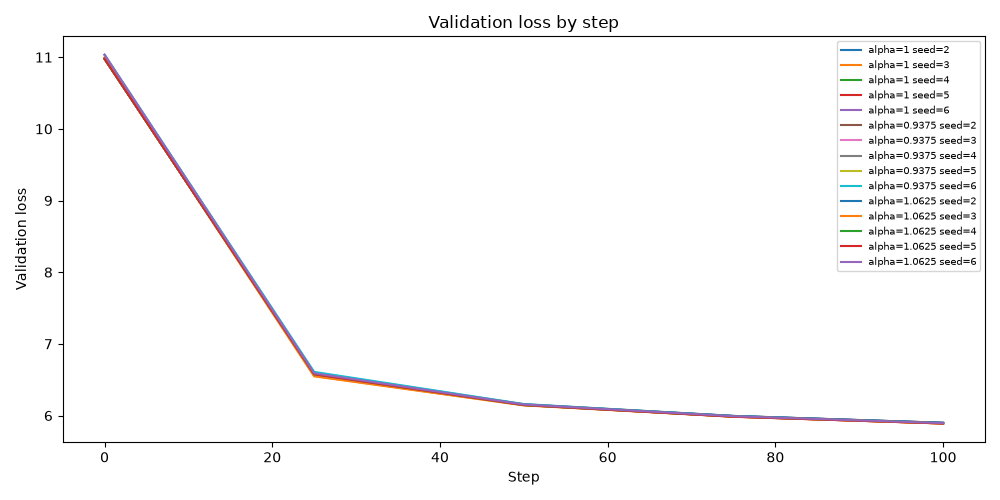

In [2]:
plt.figure(figsize=(10, 5))
for row in completed:
    plt.plot(*zip(*row['validation']), label=f"{row['label']} seed={row['seed']}")
plt.xlabel('Step'); plt.ylabel('Validation loss'); plt.legend(fontsize='x-small')
plt.title('Validation loss by step')
plt.tight_layout()


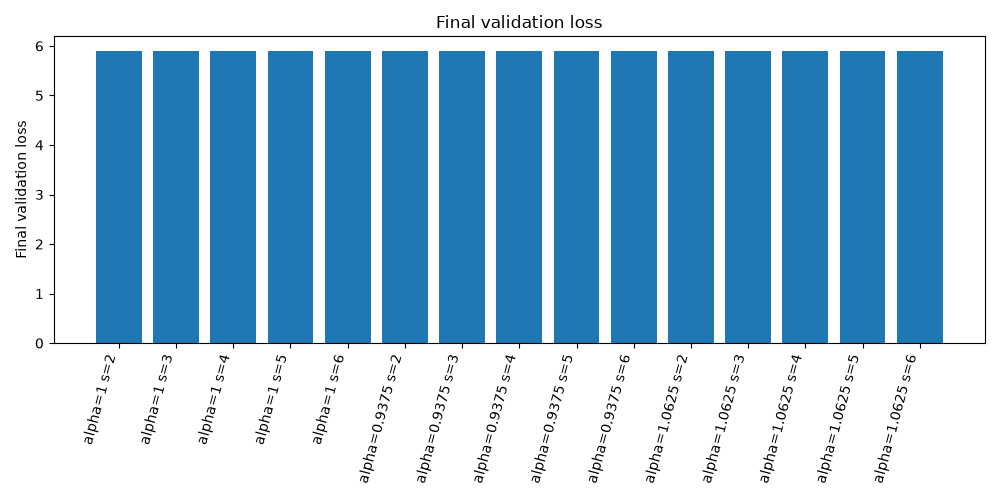

In [3]:
plt.figure(figsize=(10, 5))
plt.bar(range(len(completed)), [row['final'] for row in completed])
plt.xticks(range(len(completed)), [f"{r['label']} s={r['seed']}" for r in completed], rotation=75, ha='right'); plt.ylabel('Final validation loss')
plt.title('Final validation loss')
plt.tight_layout()


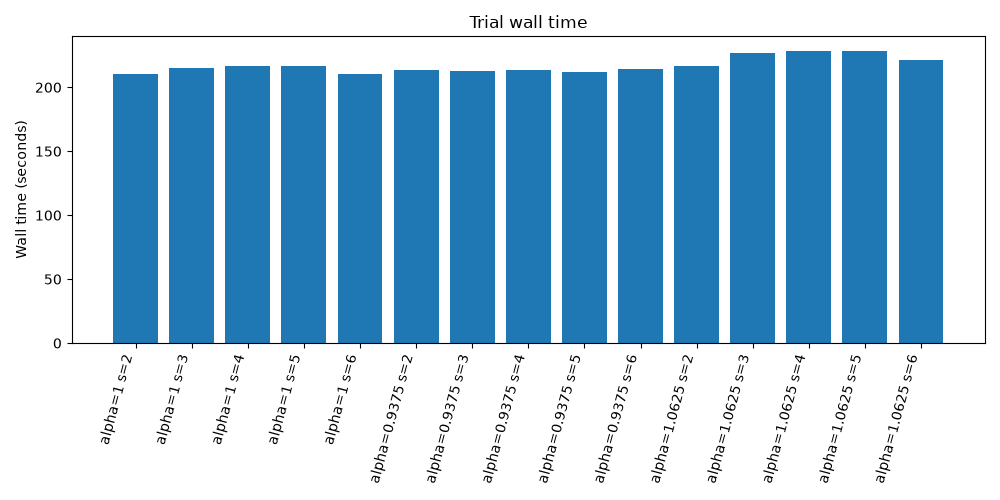

In [4]:
plt.figure(figsize=(10, 5))
plt.bar(range(len(data)), [row['seconds'] for row in data])
plt.xticks(range(len(data)), [f"{r['label']} s={r['seed']}" for r in data], rotation=75, ha='right'); plt.ylabel('Wall time (seconds)')
plt.title('Trial wall time')
plt.tight_layout()


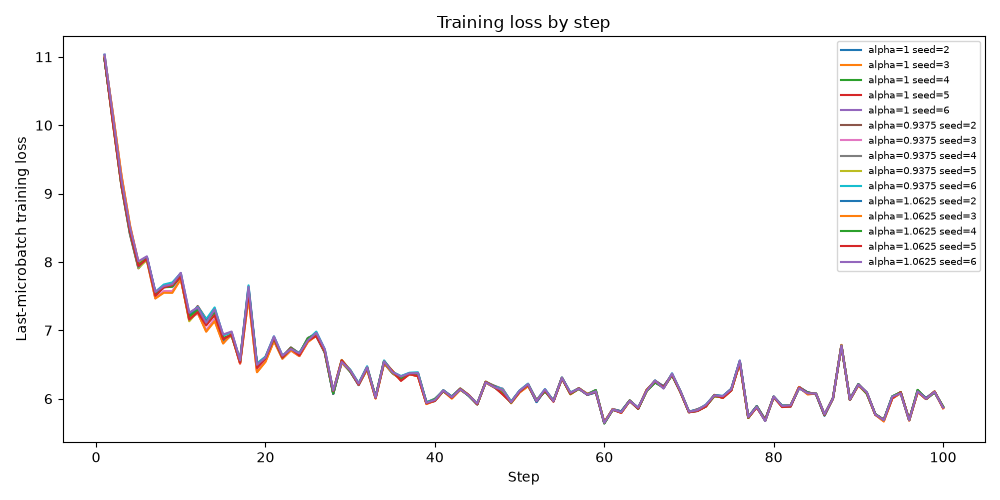

In [5]:
plt.figure(figsize=(10, 5))
for row in completed:
    if row['training']:
        plt.plot(*zip(*row['training']), label=f"{row['label']} seed={row['seed']}")
plt.xlabel('Step'); plt.ylabel('Last-microbatch training loss'); plt.legend(fontsize='x-small')
plt.title('Training loss by step')
plt.tight_layout()


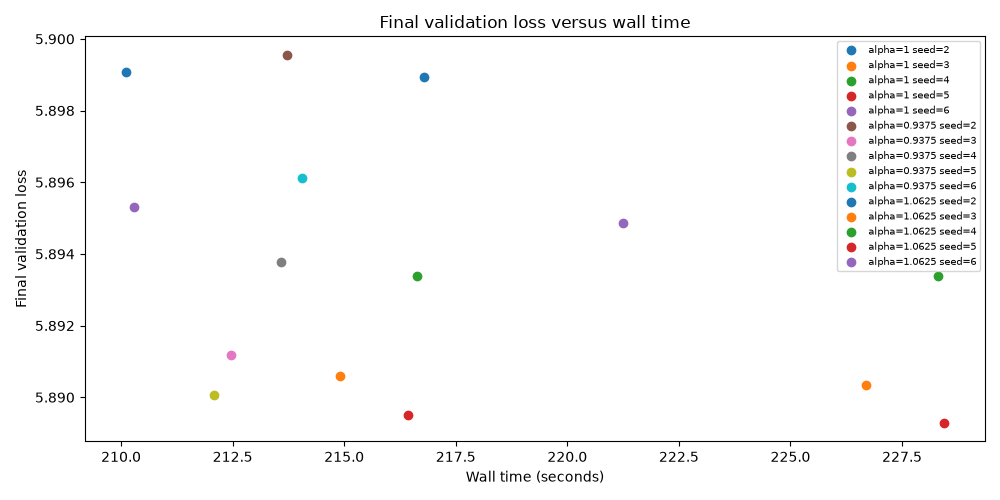

In [6]:
plt.figure(figsize=(10, 5))
for row in completed:
    plt.scatter(row['seconds'], row['final'], label=f"{row['label']} seed={row['seed']}")
plt.xlabel('Wall time (seconds)'); plt.ylabel('Final validation loss'); plt.legend(fontsize='x-small')
plt.title('Final validation loss versus wall time')
plt.tight_layout()
